# Продвинутый Python, семинар 13

**Лектор:** Петров Тимур

**Семинаристы:** Бузаев Федор, Дешеулин Олег, Коган Александра, Васина Олеся, Садуллаев Музаффар

Думая о том, где можно было бы хорошо попрактиковать анализ данных, меня вдруг осенило, что одно из явных приложений - это аналитика игр

Никакая успешная команда, выступающая на чемпионатах (будь то The International в Dota2 или же Worlds в LoL), всегда должна иметь аналитика, который будет анализировать игры и на их основе находить инсайты по тому, какую композицию выбрать или же различные синергии.

Поэтому мы будем анализировать игру, которая очень нравится самому лектору - TFT (TeamFight Tactics). Это автобаттлер, в котором ты размещаешь фигурки, апгейдишь их, кладешь итемы и так далее.

![TFT](https://genapilot.ru/wp-content/uploads/2020/03/teamfight-tactics-vyhodit-na-mobilnyh-ustrojstvah-s-ios-i-android.jpg)

Поэтому попрактикуемся на базовом датасете: [тык](https://www.kaggle.com/datasets/pvillanueva13/tft-35-500-gm-matches?select=tft_3.5_last_500_gm_match_info.csv)

##Немного про Pandas

***pandas*** — библиотека Python для работы с структурированными табличными данными (аналог таблиц Excel/баз данных). Основана на библиотеке NumPy. Название происходит от Panel Data (панельные данные в статистике).

Основные структуры данных:

- ***Series*** — одномерный массив с индексами (похож на столбец таблицы).

In [1]:
!pip install pandas

In [2]:
import pandas as pd

In [3]:
s = pd.Series([22000, 8000, 4500], index=['Аренда', 'Продукты', 'Транспорт'])

In [5]:
s

,0
Аренда,22000
Продукты,8000
Транспорт,4500


- ***DataFrame*** — двумерная таблица с именованными строками и столбцами (основной рабочий формат).
Каждый столбец — это объект Series.

In [7]:
df = pd.DataFrame({
    'имя': ['Анна', 'Иван', 'Мария'],
    'возраст': [25, 30, 28],
    'город': ['Москва', 'СПб', 'Казань']
})

In [8]:
df2 = pd.DataFrame([['Анна', 25, 'Москва'], ['Иван', 30, 'СПб']],
                   columns=['имя', 'возраст', 'город'])

In [9]:
df

,имя,возраст,город
0,Анна,25,Москва
1,Иван,30,СПб
2,Мария,28,Казань


## Грузим данные и библиотеки

In [1]:
!pip install python-dateutil

In [6]:
import numpy as np
import pandas as pd
import datetime as dt
from dateutil.parser import parse
import dateutil
import pytz
import matplotlib.pyplot as plt

In [1]:
!wget https://github.com/Palladain/Deep_Python/raw/main/Seminars/Seminar_2/archive.zip

--2025-12-10 16:55:31--  https://github.com/Palladain/Deep_Python/raw/main/Seminars/Seminar_2/archive.zip
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Palladain/Deep_Python/main/Seminars/Seminar_2/archive.zip [following]
--2025-12-10 16:55:31--  https://raw.githubusercontent.com/Palladain/Deep_Python/main/Seminars/Seminar_2/archive.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 694969 (679K) [application/zip]
Saving to: ‘archive.zip’

archive.zip         100%[===================>] 678.68K  --.-KB/s    in 0.02s   

2025-12-10 16:55:31 (36.5 MB/s) - ‘archive.zip’ saved [694969/694969]



In [2]:
!unzip archive.zip

Archive:  archive.zip
  inflating: items.json              
  inflating: tft_3.5_last_500_gm_match_info.csv  
  inflating: tft_3.5_last_500_gm_unit_info.csv  
  inflating: traits.json             


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

There are three datasets here:

`items.json` - a map from integer IDs to item names

`tft_3.5_last_500_gm_player_info.csv` - information about player placement, galaxy type, and trait bonuses

`tft_3.5_last_500_gm_unit_info.csv` - information about units and items used by each player during each match

`traits.json` - a map from IDs to trait names

## Что у нас есть?

Наши данные - это информация о матчах игроков и фигурках, которые были поставлены.

А также jsonы с информацией про предметы и особенности

## Задание 1

Загрузите данные и посмотрите на 5 рандомных строк и посмотрите информацию про каждый из датасетов

Pandas: https://pandas.pydata.org/pandas-docs/stable/getting_started/index.html

In [7]:
matches = pd.read_csv('tft_3.5_last_500_gm_match_info.csv')
matches.sample(5)

,match_id,puuid,challenger,galaxy,placement,game_datetime,Astro,Chrono,DarkStar,Set3_Celestial,...,Starship,Demolitionist,Mercenary,Set3_Blademaster,Paragon,Protector,Set3_Sorcerer,StarGuardian,MechPilot,SpacePirate
3544,NA1_3575569921,eZQHaAM5cJOMhj-6dCB9eHvf8H4e4l6ji-1-DthyRDfT70...,1,Trade Sector,1,2020-09-15 03:22:01,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
2045,NA1_3572612877,UF_I7zrdFu84TkL7y8_KUZaQEMl71j3LoH8o6_l5UtEpSP...,0,Normal Game,6,2020-09-12 20:52:22,0,0,1,0,...,0,1,1,0,0,0,1,0,1,0
963,NA1_3570835464,12TNk53_6GH55PlwDvtFwHjM0es_yoBWBMhTI4mlKe14BP...,0,Trade Sector,4,2020-09-11 09:01:58,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
2756,NA1_3573970303,jLAgsvDW70Tb3Gu11v0bY62uq7YGlkNZGzllFFkMEC2QNo...,0,Superdense Galaxy,5,2020-09-13 23:29:41,0,1,3,0,...,0,0,0,0,0,0,0,0,0,0
177,NA1_3569736938,_jhNcOxSqB7SmkO5e3Th5_dVQvdIL8Fqk1kFYsC25KcpMB...,1,Superdense Galaxy,2,2020-09-10 09:59:01,0,1,0,0,...,1,0,0,0,0,0,0,0,0,0


In [6]:
heroes = pd.read_csv('tft_3.5_last_500_gm_unit_info.csv')
heroes.sample(5)

,match_id,puuid,champion,tier,item_set_1,item_set_2,item_set_3,traits_1,traits_2,traits_3
16169,NA1_3572855643,KkBS0MYDAqtouPdvFdy1AKcDTm4V2JZxCQPpX8IqjGahpr...,Teemo,2,34.0,37.0,44.0,Astro,Sniper,NaN
4610,NA1_3575402727,5Dm0Z8JlXefiM2LLveiHOujFTcF_mWxATFtF989HnUlMjU...,Bard,2,NaN,NaN,NaN,Astro,Mystic,NaN
12328,NA1_3573528587,_8vqVBdYTdkeAWr_GvujxC6oZ_gYSrzaKhPnIA3zJSkp0V...,Graves,2,67.0,NaN,NaN,Space Pirate,Blaster,NaN
6278,NA1_3575099336,N-4thofrj29kifiUcIV_lvr0z4Ur1Z8Or68g1FNisv25wF...,Aurelion Sol,1,37.0,NaN,NaN,Rebel,Starship,NaN
18264,NA1_3572437834,sTc4BTt099egiVlO29ZK8U0dx12nOUiKFeRZejmDaGDY3J...,Rumble,2,69.0,55.0,59.0,Mech-Pilot,Demolitionist,NaN


In [7]:
heroes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35084 entries, 0 to 35083
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   match_id    35084 non-null  object 
 1   puuid       35084 non-null  object 
 2   champion    35084 non-null  object 
 3   tier        35084 non-null  int64  
 4   item_set_1  20029 non-null  float64
 5   item_set_2  12086 non-null  float64
 6   item_set_3  7846 non-null   float64
 7   traits_1    35084 non-null  object 
 8   traits_2    35084 non-null  object 
 9   traits_3    1723 non-null   object 
dtypes: float64(3), int64(1), object(6)
memory usage: 2.7+ MB


In [8]:
matches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 30 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   match_id          4000 non-null   object
 1   puuid             4000 non-null   object
 2   challenger        4000 non-null   int64 
 3   galaxy            4000 non-null   object
 4   placement         4000 non-null   int64 
 5   game_datetime     4000 non-null   object
 6   Astro             4000 non-null   int64 
 7   Chrono            4000 non-null   int64 
 8   DarkStar          4000 non-null   int64 
 9   Set3_Celestial    4000 non-null   int64 
 10  Set3_Mystic       4000 non-null   int64 
 11  Sniper            4000 non-null   int64 
 12  Vanguard          4000 non-null   int64 
 13  Cybernetic        4000 non-null   int64 
 14  Infiltrator       4000 non-null   int64 
 15  ManaReaver        4000 non-null   int64 
 16  Battlecast        4000 non-null   int64 
 17  Blaster       

## Задание 2

Посчитайте число строк в датасете matches и посмотрите на число уникальных puuid и match_id в датасете с матчами.

Сделайте вывод, сколько было матчей и сколько игроков играло. Среди игроков выделите число challengers (подсказка - поле challenger)

In [9]:
print("Rows in dataset:", len(matches))
print("Unique players:", len(matches.puuid.unique()))
print("Unique matches:", len(matches.match_id.unique()))
print("Challengers:", len(matches[matches.challenger == 1].puuid.unique()))

Rows in dataset: 4000
Unique players: 787
Unique matches: 500
Challengers: 83


## Задание 3

Уберите из названий колонок для датасета matches все подстроки "Set3_" (подсказка: функция rename())

In [10]:
matches.columns # группируем по матчам

Index(['match_id', 'puuid', 'challenger', 'galaxy', 'placement',
       'game_datetime', 'Astro', 'Chrono', 'DarkStar', 'Set3_Celestial',
       'Set3_Mystic', 'Sniper', 'Vanguard', 'Cybernetic', 'Infiltrator',
       'ManaReaver', 'Battlecast', 'Blaster', 'Set3_Brawler', 'Rebel',
       'Starship', 'Demolitionist', 'Mercenary', 'Set3_Blademaster', 'Paragon',
       'Protector', 'Set3_Sorcerer', 'StarGuardian', 'MechPilot',
       'SpacePirate'],
      dtype='object')

In [11]:
matches = matches.rename(lambda x: x.replace("Set3_", ""), axis='columns')
matches.columns

Index(['match_id', 'puuid', 'challenger', 'galaxy', 'placement',
       'game_datetime', 'Astro', 'Chrono', 'DarkStar', 'Celestial', 'Mystic',
       'Sniper', 'Vanguard', 'Cybernetic', 'Infiltrator', 'ManaReaver',
       'Battlecast', 'Blaster', 'Brawler', 'Rebel', 'Starship',
       'Demolitionist', 'Mercenary', 'Blademaster', 'Paragon', 'Protector',
       'Sorcerer', 'StarGuardian', 'MechPilot', 'SpacePirate'],
      dtype='object')

## Задание 4

Посмотрите, сколько участников было в каждом матче

In [14]:
grouped_df = matches.groupby(['match_id'])

In [15]:
for key, item in grouped_df:
    print(grouped_df.get_group(key), "\n\n")

Streaming output truncated to the last 5000 lines.
3268            1        0          0         0             0          0   
3269            0        0          1         0             0          0   
3270            0        0          1         0             0          0   
3271            0        0          0         0             0          0   

      SpacePirate  
3264            0  
3265            0  
3266            0  
3267            0  
3268            0  
3269            0  
3270            0  
3271            0  

[8 rows x 30 columns] 


            match_id                                              puuid  \
3256  NA1_3575057285  4Vi0N0An2rRjmAz6_104yXN1XVlSx2i8muNnnBccxhgE9T...   
3257  NA1_3575057285  CnUlmElyR3cZ1VKWgWRP6GrkU9RP4ZDxHzk-CNCk6zF_KW...   
3258  NA1_3575057285  pGm1tSccH4SvjtIwSuAEX9q3hwR24rkibS0nfOz30evLcX...   
3259  NA1_3575057285  5Dm0Z8JlXefiM2LLveiHOujFTcF_mWxATFtF989HnUlMjU...   
3260  NA1_3575057285  MthEJx1mf-oj56ciX2B-GhB6cdoubBf30QOPTm6Yk

In [16]:
matches.groupby(['match_id']).agg({"puuid": "nunique"}) # показать количество уникальных игроков в каждом матче

,puuid
match_id,
NA1_3569517250,8
NA1_3569539649,8
NA1_3569559117,8
NA1_3569582440,8
NA1_3569621993,8
...,...
NA1_3576354106,8
NA1_3576361605,8
NA1_3576368574,8


In [21]:
print("Participants in 1 match:", matches.groupby(['match_id']).agg({"puuid": "nunique"}).sort_values("puuid").puuid.unique()[0])

Participants in 1 match: 8


## Задание 5

Создайте колонку winner, где 1-4 место - это победа, а 5-8 - проигрыш

А также создайте колонку galaxy_numb, где каждой галактике будет присвоен свой собственный номер (подсказка: функция factorize())

И после этого посмотреть на распределение мест у challengers

In [22]:
matches["winner"] = (matches.placement <= 4).astype("int")
matches['galaxy_numb'] = pd.factorize(matches.galaxy)[0]
matches.sample(5)

,match_id,puuid,challenger,galaxy,placement,game_datetime,Astro,Chrono,DarkStar,Celestial,...,Mercenary,Blademaster,Paragon,Protector,Sorcerer,StarGuardian,MechPilot,SpacePirate,winner,galaxy_numb
2248,NA1_3573151598,VX956Ib3gQGmAZnA4Zm9W9gFo_pUOySaxcZCkyFyg_I3Hq...,0,Normal Game,1,2020-09-13 05:12:56,0,1,0,0,...,0,2,0,0,0,0,0,0,1,4
271,NA1_3569806149,ZnM9tjyLSAauonRhqSrbRGrefh7Dr7ygXFfe06watEZC3T...,0,Manatee's Delight,8,2020-09-10 13:01:14,0,0,0,0,...,0,0,0,1,2,2,0,0,0,7
2421,NA1_3573411821,OdmIXAKIF5-cSoWtPWjAToKNdr5O5tWRHNAJifo5nCHZN8...,0,Big Bang,6,2020-09-13 09:07:05,0,1,0,1,...,0,2,0,1,0,0,0,0,0,1
2524,NA1_3573499591,Ol6k2eP5-3U8kWXxOi3Y75eKY1WkOdJFcrtt-naJ_P9mlf...,0,Manatee's Delight,5,2020-09-13 14:15:12,1,1,1,1,...,0,0,0,0,0,0,0,0,0,7
3321,NA1_3575181844,Ux-GcdetJoy9dUbESUAuxkQsOIs_OGSXO_dbio8NzqVied...,0,Treasure Trove,2,2020-09-14 21:40:36,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0


In [24]:
matches[matches.challenger == 1].winner.describe()

,winner
count,750.000000
mean,0.681333
std,0.466270
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


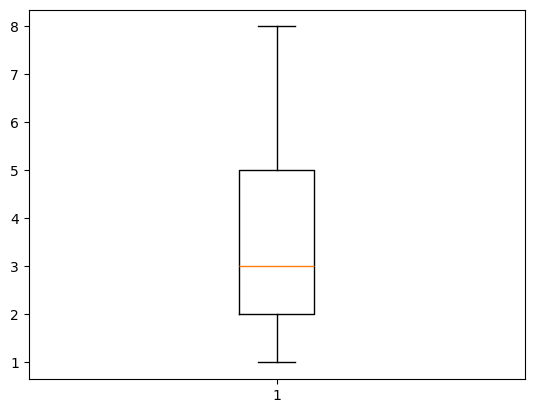

In [25]:
plt.boxplot(matches[matches.challenger == 1].placement)
plt.show()

Это есть график boxplot или "ящик с усами" - удобный график для определения ключевых характеристик распределения данных:

- ***медиана или Q2, или вторая квартиль*** (красная линия) - значение признака (место игрока), относительно которого половина объектов (игроков) имеют места 1-3, а другая половина - 3-8; то есть это значение разбивает упорядоченный набор данных на две равные части

- ***Q1 или первая квартиль, или 25-й процентиль (нижняя сторона прямоугольника)*** - величина (место 2), значение которой не превосходят 25% носителей признака (то есть 25% игроков заняли места 1-2)

- ***Q3 или третья квартиль, или 75-й процентиль (верхняя граница прямоугольника)*** - величина (место 5), котороую не превосходит 75% носителей признака (то есть 75% игроков заняли места 1-5)

- ***IQR или межквартильный размах (высота прямоугольника)*** - разница между Q3 и Q1, то есть это величина, характеризующая 50% данных (50% игроков заняли места от 2 до 5)

- ***размаж данных или минимальное / максимальное значение признака (задаёт границы усов)***

## Datetime

Чтобы решать задачи со временем, можно было бы просто вычленить из строки нужное поле и жить спокойно. Но вот, допустим, что вы хотите посмотреть не только час, но и минута, день, месяц, год и так далее. А еще у вас там часовой пояс есть какой-нибудь.

Выглядит не очень. Вот ровно для такого и существует библиотека datetime! С ее помощью можно достать из строки дату и время, преобразовать ее, привести к общему часовому поясу, посчитать разницу во времени и так далее

[Документация](https://docs.python.org/3/library/datetime.html)

Есть еще полезная надстройка над datetime - dateutil, которая в некоторых моментах позволяет более удобно работать со временем и его преобразованием

[Документация](https://dateutil.readthedocs.io/en/stable/index.html)

Какие функции есть у datetime? Начнем с преобразований из строк

* datetime.fromisoformat(s) - работает, если у вас формат выглядит как

```
YYYY-MM-DD[*HH[:MM[:SS[.fff[fff]]]][+HH:MM[:SS[.ffffff]]]]
YYY-MM-DD - год-месяц-день
HH:MM:SS - часы-минуты-секунды (может быть еще после точки миллисекунды)
+HH::MM:SS - часовой пояс не через название
```

* datetime.strptime(s, format) - по заданному шаблону преобразовать в datetime (однако тут надо задать правильный шаблон)

Форматы:

```
%a  Locale’s abbreviated weekday name.
%A  Locale’s full weekday name.      
%b  Locale’s abbreviated month name.     
%B  Locale’s full month name.
%c  Locale’s appropriate date and time representation.   
%d  Day of the month as a decimal number [01,31].    
%f  Microsecond as a decimal number [0,999999], zero-padded on the left
%H  Hour (24-hour clock) as a decimal number [00,23].    
%I  Hour (12-hour clock) as a decimal number [01,12].    
%j  Day of the year as a decimal number [001,366].   
%m  Month as a decimal number [01,12].   
%M  Minute as a decimal number [00,59].      
%p  Locale’s equivalent of either AM or PM.
%S  Second as a decimal number [00,61].
%U  Week number of the year (Sunday as the first day of the week)
%w  Weekday as a decimal number [0(Sunday),6].   
%W  Week number of the year (Monday as the first day of the week)
%x  Locale’s appropriate date representation.    
%X  Locale’s appropriate time representation.    
%y  Year without century as a decimal number [00,99].    
%Y  Year with century as a decimal number.   
%z  UTC offset in the form +HHMM or -HHMM.
%Z  Time zone name (empty string if the object is naive).    
%%  A literal '%' character.
```

* dateutil.parser.parse(s) - спарсить в datetime (без лишних заморочек с форматом)

In [27]:
d = '2022-04-26T15:14:32.001+03:00'

dt.datetime.fromisoformat(d)

datetime.datetime(2022, 4, 26, 15, 14, 32, 1000, tzinfo=datetime.timezone(datetime.timedelta(seconds=10800)))

In [28]:
from dateutil.parser import parse
#А теперь поменяем: DD-MM-YYYY
d = '05-04-2022 15:14:32.001GMT'
format = '%d-%m-%Y %H:%M:%S.%f%Z'

dt.datetime.strptime(d, format)

datetime.datetime(2022, 4, 5, 15, 14, 32, 1000)

In [29]:
print(parse(d, dayfirst=True)) #Только здесь надо было указать, что день идет первее, чем месяц

tzinfos = {'MSK': 10800}
d = 'Sat Oct 11 17:13:46 MSK 2003'
print(parse(d, tzinfos=tzinfos)) # И даже так он умеет, но надо задавать все нужные вам таймзоны

2022-04-05 15:14:32.001000+00:00
2003-10-11 17:13:46+03:00


In [30]:
dt.datetime.fromtimestamp(17456034) #можно вытаскивать также и с timestamp время

datetime.datetime(1970, 7, 22, 0, 53, 54)

Мы получили инстанс в виде datetime, из которого можно спокойно вытащить примерно все:

In [31]:
parse(d, tzinfos=tzinfos)

datetime.datetime(2003, 10, 11, 17, 13, 46, tzinfo=tzoffset('MSK', 10800))

In [32]:
d = parse(d, tzinfos=tzinfos)
print(d.year, d.month, d.day, d.hour, d.minute, d.second, d.tzinfo)

2003 10 11 17 13 46 tzoffset('MSK', 10800)


Окей, теперь хотим избавиться от тайм-зоны (или привести к какой-нибудь другой зоне, скажем, МСК подойдет)

In [33]:
d = d.astimezone(pytz.timezone('UTC'))
print(d)
d = d.astimezone(pytz.timezone('Europe/Moscow'))
print(d)

2003-10-11 14:13:46+00:00
2003-10-11 18:13:46+04:00


In [34]:
#Вывести все возможные таймзоны
for tz in pytz.all_timezones:
    print(tz)

Africa/Abidjan
Africa/Accra
Africa/Addis_Ababa
Africa/Algiers
Africa/Asmara
Africa/Asmera
Africa/Bamako
Africa/Bangui
Africa/Banjul
Africa/Bissau
Africa/Blantyre
Africa/Brazzaville
Africa/Bujumbura
Africa/Cairo
Africa/Casablanca
Africa/Ceuta
Africa/Conakry
Africa/Dakar
Africa/Dar_es_Salaam
Africa/Djibouti
Africa/Douala
Africa/El_Aaiun
Africa/Freetown
Africa/Gaborone
Africa/Harare
Africa/Johannesburg
Africa/Juba
Africa/Kampala
Africa/Khartoum
Africa/Kigali
Africa/Kinshasa
Africa/Lagos
Africa/Libreville
Africa/Lome
Africa/Luanda
Africa/Lubumbashi
Africa/Lusaka
Africa/Malabo
Africa/Maputo
Africa/Maseru
Africa/Mbabane
Africa/Mogadishu
Africa/Monrovia
Africa/Nairobi
Africa/Ndjamena
Africa/Niamey
Africa/Nouakchott
Africa/Ouagadougou
Africa/Porto-Novo
Africa/Sao_Tome
Africa/Timbuktu
Africa/Tripoli
Africa/Tunis
Africa/Windhoek
America/Adak
America/Anchorage
America/Anguilla
America/Antigua
America/Araguaina
America/Argentina/Buenos_Aires
America/Argentina/Catamarca
America/Argentina/ComodRivad

В чем проблема с таймзонами? В том, что с ними в целом сложно (вот у нас был переход на зимнее/летнее время, теперь нет, а потом опять ввели, а потом опять нет)

Поэтому такие косяки бывают всегда, но нам для точности достаточно хотя бы привести все к единому времени (так у нас данные не будут расходиться по часовым поясам)

Хорошо, привели все времена. Хотим теперь, наверное, считать diff между временами? Легко!

In [35]:
dt_1 = dt.datetime(2022, 5, 6, 14, 15, 16)
print(dt_1)
dt_2 = dt.datetime.now() #Дает время в UTC
print(dt_2)

2022-05-06 14:15:16
2025-12-08 21:49:04.145573


In [36]:
dt_2 - dt_1 #Получаем объект типа timedelta

datetime.timedelta(days=1312, seconds=27228, microseconds=145573)

In [ ]:
diff = dt_2 - dt_1
diff.days #хопа, разница в днях

131

In [37]:
dt_2 + dt.timedelta(days=15) #Хотим узнать, какое число будет через 15 дней

datetime.datetime(2025, 12, 23, 21, 49, 4, 145573)

In [38]:
format = '%d-%m-%Y'
dt.datetime.strftime(dt_2 + dt.timedelta(days=15), format) #и красивый вывод по шаблону

'23-12-2025'

А теперь к заданию!

## Задание 6.

Понять, в какие часы и дни играют challengers и выигрывают чаще. Для этого нужно создать поля days и hours с помощью datetime :)

In [39]:
matches.game_datetime = matches.game_datetime.apply(lambda x: parse(x)) # делаем через apply
matches.head(5)

,match_id,puuid,challenger,galaxy,placement,game_datetime,Astro,Chrono,DarkStar,Celestial,...,Mercenary,Blademaster,Paragon,Protector,Sorcerer,StarGuardian,MechPilot,SpacePirate,winner,galaxy_numb
0,NA1_3569517250,7AKHCtexkJJo8p04lg4shtx7n7R-uH6pQwPhBCEofkIJca...,0,Treasure Trove,1,2020-09-10 05:18:02,0,0,3,2,...,0,0,0,1,0,0,0,0,1,0
1,NA1_3569517250,0StQeXmDacsAikvEcY2ubarDZqzlEsaYsZHO6UT-UgBFY7...,0,Treasure Trove,2,2020-09-10 05:18:02,0,0,0,0,...,0,0,1,1,2,2,0,0,1,0
2,NA1_3569517250,Y0emdKI096n9-Rb0L4_I4pP_tmn_kwCtKiEjIsBRrxRqX_...,1,Treasure Trove,3,2020-09-10 05:18:02,0,1,0,0,...,1,0,0,0,0,0,0,0,1,0
3,NA1_3569517250,1vCCOdxLrdYa6NQRhywKKdZ0UNdX0nsa15Zpqo03k6QFs6...,1,Treasure Trove,4,2020-09-10 05:18:02,0,0,1,0,...,0,0,1,1,2,1,0,0,1,0
4,NA1_3569517250,mC0hMfKYhejc1U1aJE7iTOTn6TUDkY4apfQhdw2Pvp_jV3...,0,Treasure Trove,5,2020-09-10 05:18:02,0,0,0,1,...,0,0,1,1,0,0,0,0,0,0


In [40]:
matches['hour'] = matches.game_datetime.apply(lambda x: x.hour)
matches['day'] = matches.game_datetime.apply(lambda x: x.day)

In [42]:
matches[matches.challenger == 1].groupby("hour").agg({"winner": "mean"})

,winner
hour,
0,0.750000
1,0.687500
2,0.714286
3,0.675000
4,0.709677
5,0.680851
6,0.727273
7,0.684211
8,0.742857


In [43]:
matches[matches.challenger == 1].groupby("hour").agg({"winner": "mean"}).reset_index()

,hour,winner
0,0,0.750000
1,1,0.687500
2,2,0.714286
3,3,0.675000
4,4,0.709677
5,5,0.680851
6,6,0.727273
7,7,0.684211
8,8,0.742857
9,9,0.774194


In [47]:
matches[matches.challenger == 1].groupby("hour").agg({"winner": "mean"}).reset_index().sort_values("winner", ascending=False).head(5)

,hour,winner
13,13,0.800000
22,22,0.781250
11,11,0.777778
9,9,0.774194
0,0,0.750000


In [44]:
matches[matches.challenger == 1].groupby("day").agg({"winner": "mean"}).reset_index().sort_values("winner", ascending=False).head(5)

,day,winner
5,15,0.750000
1,11,0.709220
3,13,0.705882
6,16,0.666667
4,14,0.653061


## Задание 7.

Сджойнить таблицы с героями и матчами и выбрать самого лучшего чемпиона (самое больше число побед)

In [48]:
merged_matches = pd.merge(matches, heroes, on=['match_id', 'puuid'], how='inner') #делаем merge
merged_matches.sample(5)

,match_id,puuid,challenger,galaxy,placement,game_datetime,Astro,Chrono,DarkStar,Celestial,...,hour,day,champion,tier,item_set_1,item_set_2,item_set_3,traits_1,traits_2,traits_3
1690,NA1_3569748740,_jhNcOxSqB7SmkO5e3Th5_dVQvdIL8Fqk1kFYsC25KcpMB...,1,Salvage World,1,2020-09-10 10:41:46,0,0,0,0,...,10,10,Viktor,2,37.0,33.0,44.0,Battlecast,Sorcerer,NaN
8290,NA1_3570795841,L7BhIfvSuA60yFlkMt1Y19OOj2COEBgXIuEV3vLvWTiZdW...,0,Big Bang,6,2020-09-11 08:47:06,0,1,0,0,...,8,11,Irelia,2,66.0,NaN,NaN,Cybernetic,Mana-Reaver,Blademaster
22996,NA1_3573633633,anNGwRNatMIJ40k1vAY8tV5h0nI9UU-EYCuZbu5g0fqbNb...,0,Manatee's Delight,5,2020-09-13 17:12:52,0,1,0,0,...,17,13,Leona,2,36.0,NaN,NaN,Cybernetic,Vanguard,NaN
15266,NA1_3572175404,Nd8kYXVun_DNR1T9aZbS_CSSmPgLeQRI9njED7gWDYLoRx...,0,Treasure Trove,7,2020-09-12 08:39:28,0,0,0,1,...,8,12,Lulu,1,NaN,NaN,NaN,Celestial,Mystic,NaN
8057,NA1_3570830649,LdgjYAOps5pbCW0tRgUxZ8p5VyxgZN_TCOrjTYwg2MSsxz...,0,Trade Sector,3,2020-09-11 08:05:23,0,1,0,0,...,8,11,Kog'Maw,3,57.0,24.0,NaN,Battlecast,Blaster,NaN


In [ ]:
merged_matches.groupby("champion").agg({"winner": "mean"}).reset_index().sort_values("winner", ascending=False).head(5)

,champion,winner
45,Urgot,0.692008
51,Xerath,0.671458
43,Thresh,0.653930
27,Lulu,0.650273
9,Ekko,0.635000


## Задание 8.

Посчитать, какие итемы чаще всего используют и как они называются

Иногда для того, чтобы выгрузить данные, вам надо будет подгружать json-файлы. Делается это с помощью библиотеки json

[Документация](https://docs.python.org/3/library/json.html)

Базово, для того, чтобы выгрузить json, нужно использовать load (когда грузим из файла) или loads (если хотим выгрузить из строки)

In [49]:
import json

with open('items.json') as json_data:
    items = json.load(json_data)
items = pd.DataFrame(items) # А дальше можно просто запихнуть это в DataFrame, очень удобно!

In [50]:
res = np.unique(np.array(heroes[["item_set_1", "item_set_2", "item_set_3"]]).ravel(), return_counts=True)
# В unique есть аргумент return_counts, который вам дает еще и подсчет уникальных значений!

count_items = pd.DataFrame(res)
count_items = count_items.T #умеем прям как в numpy!
count_items.columns = ["id", "cnt"]
count_items

,id,cnt
0,1.0,196.0
1,2.0,351.0
2,3.0,345.0
3,4.0,387.0
4,5.0,272.0
5,6.0,310.0
6,7.0,243.0
7,8.0,49.0
8,9.0,141.0
9,11.0,547.0


In [51]:
pd.merge(items, count_items, on=['id'], how='inner').sort_values("cnt", ascending=False).head(5)

,id,name,cnt
13,15,Guardian Angel,2447.0
10,12,Giant Slayer,2041.0
33,44,Seraph's Embrace,1889.0
45,67,Zephyr,1464.0
30,37,Morellonomicon,1403.0


##И напоследок

Так как мы люди современные, то и методы будем использовать современные. Сейчас EDA в целом умещается в одну компактную библиотеку [ydata-profiling](https://github.com/ydataai/ydata-profiling), в которой мы уже сразу же сможем посмотреть все необходимое

In [3]:
!pip install ydata-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 398.7/398.7 kB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 72.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 3.0 MB/s eta 0:00:00


In [8]:
from ydata_profiling import ProfileReport

profile = ProfileReport(matches, title='TFT Report')
profile.to_file("report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 30/30 [00:00<00:00, 30.53it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Получаем файл, внутри которого уже есть сразу приличная часть графиков, которые нам необходимы были бы (даже на сыром датасете)